# Complex geometry

Geometry defined with `&GEOM` is made of triangles. fdsreader reads its boundary data (one
value per triangle) and geometry slices.

Run FDS on both inputs first:

- `fds_data/sphere_radiate.fds`: a sphere that radiates, with the radiative heat flux on its
  surface
- `fds_geomslices/cone_1mesh.fds`: a cone in a coarse mesh, with `SLICETYPE='CUT_CELLS'`

In [1]:
import pyvista as pv

import fdsreader as fds

# Render 3D views as static images, so they are stored in the notebook. Use "trame" or
# remove this line to rotate the views interactively.
pv.set_jupyter_backend("static")
pv.global_theme.window_size = [800, 550]

## Boundary data on a geometry

`sim.geom_data` holds one entry per boundary quantity. Each has the `vertices` and `faces`
(triangles as vertex indices) of the geometry and one value per face and output time.

In [2]:
sim = fds.Simulation("./fds_data")
flux = sim.geom_data.filter_by_quantity("Radiative Heat Flux")[0]
print(flux)
print("vertices:", flux.vertices.shape, " faces:", flux.faces.shape, " time steps:", len(flux.data))

GeomBoundary(quantity=Quantity('RADIATIVE HEAT FLUX'))
vertices: (41168, 3)  faces: (20020, 3)  time steps: 1


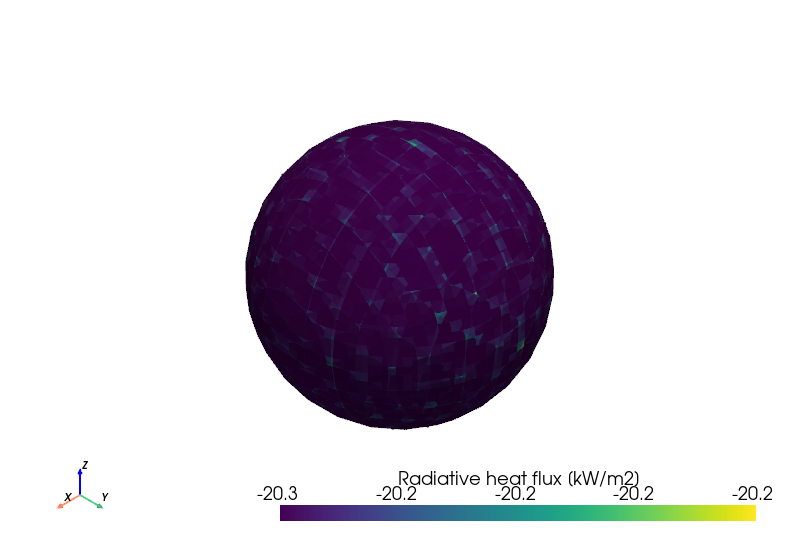

In [3]:
sphere = pv.PolyData.from_regular_faces(flux.vertices, flux.faces)
sphere.plot(scalars=flux.data[-1], scalar_bar_args={"title": "Radiative heat flux [kW/m2]"})

The flux is nearly the same everywhere, as expected for this verification case of a
uniformly radiating sphere.

## Cut cells

`&SLCF ... SLICETYPE='CUT_CELLS'` writes the grid cells that are cut by the geometry. They
are read as a geometry slice, again as triangles.

GeomSlice(quantity=Quantity('Cut Cells')) (3140, 3)


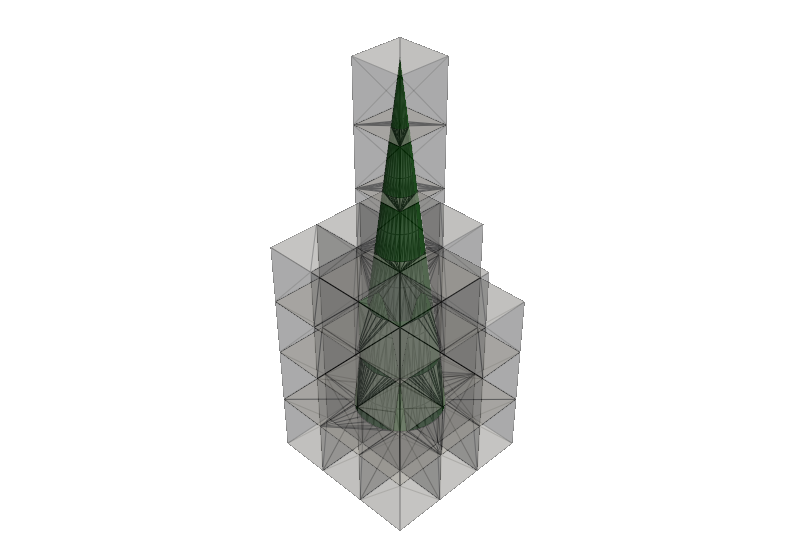

In [4]:
sim_cone = fds.Simulation("./fds_geomslices")
cut_cells = sim_cone.geomslices[0]
cone = sim_cone.geom_data[0]
print(cut_cells, cut_cells.faces.shape)

plotter = pv.Plotter()
plotter.add_mesh(
    pv.PolyData.from_regular_faces(cut_cells.vertices, cut_cells.faces), color="lightgrey", opacity=0.3, show_edges=True
)
plotter.add_mesh(pv.PolyData.from_regular_faces(cone.vertices, cone.faces), color="green")
plotter.show()

More in the API reference for [geometry](https://fdsreader.readthedocs.io/en/latest/api/geom.html) and
[geometry slices](https://fdsreader.readthedocs.io/en/latest/api/slcf.html).